<a href="https://colab.research.google.com/github/victoriariosvzz2/Rare-Disease-MVA-Hackathon-2026/blob/main/track1_variant_prediction/notebooks/track1_final_submission_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 🧬 Track 1: Variant Prediction
### MVA Rare Disease Hackathon 2026
**Author:** Victoria Rios-Vazquez
**Contact:** victoria.rios.vzz@gmail.com

---

**Proband:** a child with a real, undiagnosed rare disease &nbsp;|&nbsp;
**Data:** whole-genome
sequencing (~5 million variants) + a clinical symptom summary &nbsp;|&nbsp; **Assembly:** GRCh38

---

### The Goal

Predict the specific genetic variant(s) that may be driving the child's condition using their clinical symptoms and genomic data.

---

### Initial Notes

Before writing this version, the actual current literature was reviewed rather than
assumed. Three sources anchor the changes below:

- **Stenton et al. (CAGI6 Rare Genomes Project)**: the benchmark this hackathon's own FAQ points to, found that top-performing teams recalled causal variants by
  prioritizing calls that were rare, predicted deleterious, segregating correctly, and
  phenotype-consistent, with **manual review as an accepted, expected part of the top
  submissions**, not a workaround.
- **AI-MARRVEL** (NEJM AI) formalizes gene constraint, splicing prediction, and
  inheritance pattern into a 56-feature model trained on 3.5M+ variants from diagnosed
  cases.
- **LA-MARRVEL and RareCollab (2026)**: the actual current frontier is to add a
  **language-aware LLM reranking layer** on top of structured evidence, substantially
  outperforming classic tools: reported gains of roughly 20-27% in top-10 recall over
  Exomiser. This is architecturally new versus everything in v1-v3 of this notebook.

**What this version does NOT claim to be:** a reimplementation of AI-MARRVEL, 3ASC, or
LA-MARRVEL. Those are trained ML systems and retrieval-augmented production tools
built by dedicated teams over years. This is a transparent, documented approximation
of their *architecture*, built from public data and a single LLM call, which is a
fundamentally different (and more modest) thing than what those systems are.


### Table of Contents

| Chapter | What happens |
|---|---|
| 1 | Patient information |
| 2 | From 5,000,000 variants to a workable set |
| 3 | Giving variants meaning (VEP, genome-wide) |
| 4 | Nature's rules (inheritance modeling) |
| 5 | Does biology agree with the clinic? (ontology-based phenotype similarity) |
| 6 | First verdict: coarse ranking → shortlist |
| 7 | Deep evidence enrichment (CADD/REVEL/AlphaMissense, LOH, SpliceAI, **gene constraint**) |
| 8 | **ACMG/AMP-inspired evidence tagging** |
| 9 | Refined numeric ranking |
| 10 | **LLM-based holistic reranking** (the 2026-frontier step) |
| 11 | Building the submission |
| 12 | Contextualizing results with current literature |
| 13 | Telling the story: methods report |
| Epilogue | How this approach compares to state-of-the-art? |


## Setup: Environment & Data

First step: connect this notebook to my actual GitHub repo and install everything the pipeline needs. Nothing analytical happens yet, this is just making sure the workspace is ready and my credentials (GitHub, Hugging Face, and Anthropic) are loaded securely from Colab's secrets.

In [3]:
# ── Cell 1: Environment setup ──
from google.colab import userdata
import os, time

github_token = userdata.get('GITHUB_TOKEN')
hf_token = userdata.get('HF_TOKEN')
anthropic_api_key = userdata.get('ANTHROPIC_API_KEY')

REPO_DIR = "/content/Rare-Disease-MVA-Hackathon-2026"
DATA_DIR = "/content/data"
TRACK1_DIR = f"{REPO_DIR}/track1_variant_prediction"

os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.isdir(REPO_DIR):
    !git clone https://{github_token}@github.com/victoriariosvzz2/Rare-Disease-MVA-Hackathon-2026.git {REPO_DIR}

%cd {REPO_DIR}
!git config --global user.email "victoria.riosvazquez@radboudumc.nl"
!git config --global user.name "victoriariosvzz2"

!pip install -q huggingface_hub cyvcf2 python-docx requests pandas intervaltree openpyxl pyhpo myvariant anthropic

PIPELINE_START_TIME = time.time()
print("Environment ready.")


Cloning into '/content/Rare-Disease-MVA-Hackathon-2026'...
remote: Enumerating objects: 57, done.
remote: Counting objects: 100% (57/57), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 57 (delta 28), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (57/57), 106.11 KiB | 1.26 MiB/s, done.
Resolving deltas: 100% (28/28), done.
/content/Rare-Disease-MVA-Hackathon-2026
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 44.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.1/52.1 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 6.0 MB/s eta 0:00:00
Environment ready.


Now I pull down the three files I actually need: the VCF (called variants), its index, and the clinical phenotype document. Notice I'm not downloading the raw FASTQ files, I confirmed earlier those are ~85GB of raw reads I don't need for variant-level analysis, versus 0.3GB for the VCF itself.

In [2]:

# ── Cell 2: Ensure the proband's data is downloaded ──
from huggingface_hub import hf_hub_download

DATASET_REPO = "SageBio/mva-hackathon-2026-data"
files_to_get = [
    "WGS_EX2312012_HGWCNDSX7.vcf.gz",
    "WGS_EX2312012_HGWCNDSX7.vcf.gz.tbi",
    "Challenge_Clinical_Phenotype_1.docx",
]

paths = {}
for fname in files_to_get:
    local_path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(local_path):
        local_path = hf_hub_download(repo_id=DATASET_REPO, filename=fname, repo_type="dataset",
                                       local_dir=DATA_DIR, token=hf_token)
    paths[fname] = local_path
    print(f"OK: {fname}")

VCF_PATH = paths["WGS_EX2312012_HGWCNDSX7.vcf.gz"]
PHENOTYPE_DOC = paths["Challenge_Clinical_Phenotype_1.docx"]


OK: WGS_EX2312012_HGWCNDSX7.vcf.gz
OK: WGS_EX2312012_HGWCNDSX7.vcf.gz.tbi
OK: Challenge_Clinical_Phenotype_1.docx


## Chapter 1: Understanding the Patient

Before looking at a single variant, I visualized myself in the clinical picture: what symptoms does this child actually have, in the standardized HPO vocabulary clinicians use? This becomes the phenotype signal the rest of the pipeline reasons about.

In [3]:

# ── Cell 3: Extract the structured HPO term table from the clinical document ──
from docx import Document
import pandas as pd

doc = Document(PHENOTYPE_DOC)
hpo_features = []
for table in doc.tables:
    rows = [[c.text.strip() for c in row.cells] for row in table.rows]
    header, data_rows = rows[0], rows[1:]
    for r in data_rows:
        hpo_features.append(dict(zip(header, r)))

hpo_df = pd.DataFrame(hpo_features)
patient_hpo_ids = hpo_df["HPO ID"].dropna().unique().tolist()

print(f"Extracted {len(hpo_df)} clinical features, mapping to {len(patient_hpo_ids)} unique HPO terms:\n")
print(hpo_df[["Clinical Feature", "HPO ID"]].to_string(index=False))


Extracted 8 clinical features, mapping to 8 unique HPO terms:

                   Clinical Feature     HPO ID
                   Rhabdomyosarcoma HP:0002859
                   Nephrocalcinosis HP:0000121
                      Short stature HP:0004322
Low muscle mass / Failure to thrive HP:0001508
Low muscle mass / Failure to thrive HP:0003202
                    Premature birth HP:0001622
              Very low birth weight HP:0001518
    Parental recurrent miscarriages HP:0200067


Let's visualize it.

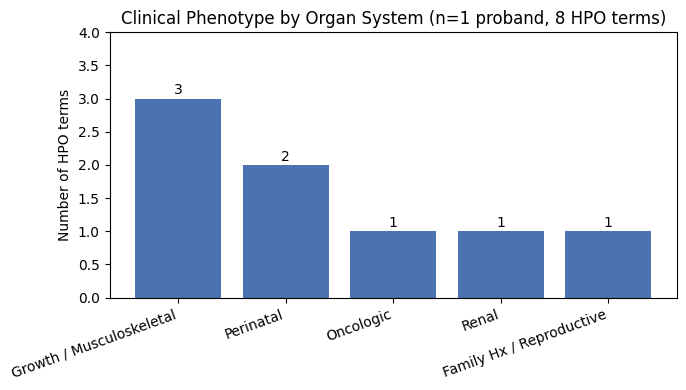

In [4]:
# ── Organ-system breakdown of the phenotype ──
import matplotlib.pyplot as plt

# Manual categorization by HPO ID
organ_system_map = {
    "HP:0002859": "Oncologic",                    # Rhabdomyosarcoma
    "HP:0000121": "Renal",                        # Nephrocalcinosis
    "HP:0004322": "Growth / Musculoskeletal",      # Short stature
    "HP:0001508": "Growth / Musculoskeletal",      # Failure to thrive
    "HP:0003202": "Growth / Musculoskeletal",      # Skeletal muscle atrophy
    "HP:0001622": "Perinatal",                     # Premature birth
    "HP:0001518": "Perinatal",                     # Small for gestational age
    "HP:0200067": "Family Hx / Reproductive",      # Recurrent spontaneous abortion
}

hpo_df["organ_system"] = hpo_df["HPO ID"].map(organ_system_map)
system_counts = hpo_df["organ_system"].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(system_counts.index, system_counts.values, color="#4C72B0")
ax.set_ylabel("Number of HPO terms")
ax.set_title("Clinical Phenotype by Organ System (n=1 proband, 8 HPO terms)")
ax.set_ylim(0, max(system_counts.values) + 1)
plt.xticks(rotation=20, ha="right")

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{int(height)}", xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10)

plt.tight_layout()
plt.show()

Reading this chart, this is a categorical breakdown but not a statistical distribution, with n=1 patient, there's no population
to show variance across. Four things worth noting:

1. **The phenotype is dominated by one underlying problem told three ways.** Short
   stature, failure to thrive, and skeletal muscle atrophy are three HPO terms
   describing the same growth failure this is really ~5 independent clinical axes.
2. **One clinical feature split into two HPO codes.** ("Low muscle mass / Failure to
   thrive" -> HP:0001508 + HP:0003202). The source document had already normalized
   compound observations into precise ontology terms before we ever touched it.
3. **Raw counts understate the oncologic signal.** Rhabdomyosarcoma is one bar out of
   five categories, but pediatric rhabdomyosarcoma is rare enough that it carries far
   more diagnostic weight than "1/8" suggests a real limitation of any
   count-based summary, including phenotype-similarity scoring itself.
4. **The reproductive/family-history term isn't a symptom of the child.**
   it's evidence about the parents, and the strongest single hint toward autosomal
   recessive inheritance in this whole table. It's categorically different from the
   other seven and shouldn't be read as "one more symptom."

## Chapter 2: From Five Million Variants to a Workable Set

To know which parts of the genome are protein-coding, I need a gene annotation file. Rather than hardcoding a version number that'll go stale, I look up whatever the current release actually is at run time, small thing, but it's what keeps this pipeline from silently breaking a year from now.

In [5]:

# ── Cell 4: Resolve the current GENCODE release dynamically ──
import re, requests

def find_latest_gencode_basic_gtf_url():
    listing_url = "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/latest_release/"
    listing = requests.get(listing_url).text
    match = re.search(r'(gencode\.v\d+\.basic\.annotation\.gtf\.gz)', listing)
    if not match:
        raise RuntimeError(f"Could not auto-discover the latest GENCODE filename. Check: {listing_url}")
    fname = match.group(1)
    return listing_url + fname, fname

gtf_url, gtf_fname = find_latest_gencode_basic_gtf_url()
print(f"Resolved current GENCODE release: {gtf_fname}")

gtf_local = os.path.join(DATA_DIR, gtf_fname)
if not os.path.exists(gtf_local):
    r = requests.get(gtf_url, stream=True)
    r.raise_for_status()
    with open(gtf_local, "wb") as f:
        for chunk in r.iter_content(chunk_size=1 << 16):
            f.write(chunk)
print(f"Downloaded to: {gtf_local}")


Resolved current GENCODE release: gencode.v50.basic.annotation.gtf.gz
Downloaded to: /content/data/gencode.v50.basic.annotation.gtf.gz


I parse that annotation file down to just the protein-coding exons and build a fast lookup structure, an interval tree, so I can instantly check whether any given genomic position falls inside a coding region. This is the one and only filter I apply before annotation, and it's disease-agnostic: every gene in the genome gets treated identically here.

In [6]:

# ── Cell 5: Parse protein-coding exons into a per-chromosome interval index ──
import gzip
from intervaltree import IntervalTree
from collections import defaultdict

exon_trees = defaultdict(IntervalTree)
gene_type_pat = re.compile(r'gene_type "([^"]+)"')
gene_name_pat = re.compile(r'gene_name "([^"]+)"')
SPLICE_BUFFER = 10

n_exons = 0
with gzip.open(gtf_local, "rt") as f:
    for line in f:
        if line.startswith("#"):
            continue
        fields = line.rstrip("\n").split("\t")
        if len(fields) < 9 or fields[2] != "CDS":
            continue
        gt_match = gene_type_pat.search(fields[8])
        if not gt_match or gt_match.group(1) != "protein_coding":
            continue
        chrom = fields[0].replace("chr", "")
        start, end = int(fields[3]), int(fields[4])
        gene_match = gene_name_pat.search(fields[8])
        gene_name = gene_match.group(1) if gene_match else None
        exon_trees[chrom][max(1, start - SPLICE_BUFFER):end + SPLICE_BUFFER + 1] = gene_name
        n_exons += 1

print(f"Indexed {n_exons:,} protein-coding exon intervals across {len(exon_trees)} chromosomes.")


Indexed 2,599,009 protein-coding exon intervals across 25 chromosomes.


This is where I go through all ~5 million variants in this child's genome, one by one, and keep only the ones landing in a coding exon. I'm also quietly tallying the overall rate of heterozygous vs. homozygous calls genome-wide while I'm at it, that baseline becomes useful evidence later, in the structural-variant check.

In [7]:

# ── Cell 6: Genome-wide scan -- keep exonic variants, AND tally genome-wide zygosity ──
from cyvcf2 import VCF

vcf = VCF(VCF_PATH)
PROBAND_ID = vcf.samples[0]
print(f"Proband ID (from VCF): {PROBAND_ID}")

exonic_rows = []
n_total_scanned = 0
n_het_genomewide = 0
n_hom_genomewide = 0

for variant in vcf:
    n_total_scanned += 1
    gt = variant.genotypes[0]
    is_het = (gt[0] != gt[1]) and (0 in (gt[0], gt[1]))
    is_hom_alt = gt[0] == gt[1] and gt[0] >= 1
    if is_het:
        n_het_genomewide += 1
    elif is_hom_alt:
        n_hom_genomewide += 1

    chrom = str(variant.CHROM)
    tree = exon_trees.get(chrom)
    if tree is None:
        continue
    hits = tree[variant.POS]
    if not hits:
        continue
    zygosity = "HOM" if gt[0] == 1 and gt[1] == 1 else ("HET" if 1 in (gt[0], gt[1]) else "REF")
    if zygosity == "REF":
        continue
    genes_here = sorted(set(iv.data for iv in hits if iv.data))
    for gene in genes_here:
        exonic_rows.append({
            "gene_from_exon_index": gene, "chrom": chrom, "pos": variant.POS,
            "ref": variant.REF, "alt": variant.ALT[0], "n_alt_alleles": len(variant.ALT),
            "zygosity": zygosity,
        })

exonic_df = pd.DataFrame(exonic_rows)
GENOME_WIDE_HET_RATE = n_het_genomewide / max(1, (n_het_genomewide + n_hom_genomewide))

print(f"Scanned {n_total_scanned:,} total variants genome-wide.")
print(f"Retained {len(exonic_df):,} (variant, gene) pairs overlapping protein-coding exons.")
print(f"Genome-wide baseline heterozygosity rate: {GENOME_WIDE_HET_RATE:.3f}")


Proband ID (from VCF): WGS_EX2312012
Scanned 5,012,204 total variants genome-wide.
Retained 33,670 (variant, gene) pairs overlapping protein-coding exons.
Genome-wide baseline heterozygosity rate: 0.616


## Chapter 3: Giving Variants Meaning

Every retained variant now gets sent, in batches, to Ensembl's variant annotation API. This is what turns a bare position and base change into something meaningful: what gene is this in, what does it do to the protein, how does it compare to population databases?

In [8]:

# ── Cell 7: Batch-annotate every exonic variant via Ensembl VEP (POST, 200/request) ──
unique_variants = exonic_df[["chrom", "pos", "ref", "alt"]].drop_duplicates().reset_index(drop=True)
print(f"Annotating {len(unique_variants):,} unique variants...")

def to_vep_region_string(chrom, pos, ref, alt):
    return f"{chrom} {pos} . {ref} {alt} . . ."

BATCH_SIZE = 200
vep_results = []

for start in range(0, len(unique_variants), BATCH_SIZE):
    batch = unique_variants.iloc[start:start + BATCH_SIZE]
    variant_strings = [to_vep_region_string(r.chrom, r.pos, r.ref, r.alt) for r in batch.itertuples()]

    resp = None
    for attempt in range(3):
        r = requests.post(
            "https://rest.ensembl.org/vep/human/region",
            headers={"Content-Type": "application/json", "Accept": "application/json"},
            json={"variants": variant_strings},
        )
        if r.status_code == 200:
            resp = r.json()
            break
        time.sleep(2 * (attempt + 1))

    if resp is None:
        print(f"WARNING: batch at row {start} failed after retries.")
        resp = [None] * len(batch)

    for i, row in enumerate(batch.itertuples()):
        match = None
        if i < len(resp) and resp[i] and resp[i].get("start") == row.pos:
            match = resp[i]
        else:
            for item in resp:
                if item and item.get("start") == row.pos:
                    match = item
                    break
        vep_results.append({"chrom": row.chrom, "pos": row.pos, "ref": row.ref, "alt": row.alt, "vep": match})

    time.sleep(1)

print(f"Annotation complete: {len(vep_results):,} variants processed.")


Annotating 33,211 unique variants...
Annotation complete: 33,211 variants processed.


The raw API response is deeply nested JSON, this cell pulls out just what I need into a clean table: consequence type, SIFT/PolyPhen predictions, population frequency, and clinical significance, one row per variant.

In [9]:

# ── Cell 8: Flatten VEP output into analysis-ready columns ──
def extract_vep_features(entry):
    ann = entry["vep"]
    out = {"most_severe_consequence": None, "canonical_gene": None,
           "sift": None, "polyphen": None, "gnomad_af": None, "clinvar_significance": None}
    if not ann:
        out["most_severe_consequence"] = "NO_ANNOTATION"
        return out
    out["most_severe_consequence"] = ann.get("most_severe_consequence")
    for tc in ann.get("transcript_consequences", []):
        if tc.get("canonical") == 1:
            out["canonical_gene"] = tc.get("gene_symbol")
            out["sift"] = tc.get("sift_prediction")
            out["polyphen"] = tc.get("polyphen_prediction")
    for cv in ann.get("colocated_variants", []):
        freqs = cv.get("frequencies", {})
        for allele_freqs in freqs.values():
            gaf = allele_freqs.get("gnomadg") or allele_freqs.get("gnomade")
            if gaf is not None:
                out["gnomad_af"] = gaf
        if cv.get("clin_sig"):
            out["clinvar_significance"] = ",".join(cv["clin_sig"])
    return out

vep_flat = pd.DataFrame([extract_vep_features(e) for e in vep_results])
vep_flat = pd.concat([pd.DataFrame(vep_results)[["chrom", "pos", "ref", "alt"]], vep_flat], axis=1)

annotated_df = exonic_df.merge(vep_flat, on=["chrom", "pos", "ref", "alt"], how="left")
annotated_df["gene"] = annotated_df["canonical_gene"].fillna(annotated_df["gene_from_exon_index"])

print(f"Final annotated variant table: {len(annotated_df):,} rows.")
annotated_df[["gene", "chrom", "pos", "ref", "alt", "zygosity", "most_severe_consequence",
              "sift", "polyphen", "gnomad_af", "clinvar_significance"]].head(10)


Final annotated variant table: 33,670 rows.


,gene,chrom,pos,ref,alt,zygosity,most_severe_consequence,sift,polyphen,gnomad_af,clinvar_significance
0,SAMD11,1,924533,A,G,HOM,synonymous_variant,None,None,0.8213,None
1,SAMD11,1,942451,T,C,HOM,missense_variant,None,None,0.9998,"uncertain_significance,benign"
2,NOC2L,1,946247,G,A,HOM,synonymous_variant,None,None,0.4812,None
3,NOC2L,1,952421,A,G,HOM,missense_variant,None,None,0.9341,None
4,NOC2L,1,953259,T,C,HOM,missense_variant,None,None,0.9341,None
5,NOC2L,1,953279,T,C,HOM,missense_variant,None,None,0.9341,None
6,NOC2L,1,953778,G,C,HOM,splice_donor_region_variant,None,None,0.9113,None
7,NOC2L,1,953779,A,C,HOM,splice_donor_region_variant,None,None,0.9113,None
8,NOC2L,1,955641,G,A,HOM,missense_variant,None,None,0.8778,None
9,NOC2L,1,955679,C,T,HOM,synonymous_variant,None,None,0.4931,None


## Chapter 4: Nature's Rules (Selecting Initial Candidates)

This condition is autosomal recessive, so I'm not interested in just any variant. I'm looking for genes where the child has either two copies of the same damaged variant, or two different damaged variants in the same gene (one from each parent). This step builds that candidate list, genome-wide, with no gene list assumed going in.

In [10]:

# ── Cell 9: Build inheritance-consistent candidates, genome-wide ──
candidates = []
for gene, gene_df in annotated_df.groupby("gene"):
    if pd.isna(gene) or gene is None:
        continue
    for _, row in gene_df[gene_df["zygosity"] == "HOM"].iterrows():
        candidates.append({"gene": gene, "inheritance_model": "homozygous", "variant_rows": [row]})
    het_rows = gene_df[gene_df["zygosity"] == "HET"].to_dict("records")
    for i in range(len(het_rows)):
        for j in range(i + 1, len(het_rows)):
            candidates.append({"gene": gene, "inheritance_model": "compound_het_candidate",
                                "variant_rows": [het_rows[i], het_rows[j]]})

print(f"Total inheritance-consistent candidates genome-wide: {len(candidates):,}")
print(f"Spanning {len(set(c['gene'] for c in candidates))} distinct genes.")


Total inheritance-consistent candidates genome-wide: 105,288
Spanning 8876 distinct genes.


## Chapter 5: Does Biology Agree with the Clinic? (Ontology-Based)

Here's where the clinical picture from Cell 3 finally re-enters, but computationally, not by me picking genes I recognize. I use the same ontology-based method real diagnostic tools use to score how well each gene's known disease phenotype overlaps with this child's actual symptoms.

In [11]:

# ── Cell 10: Build the patient's HPO set and a semantic similarity function ──
from pyhpo import Ontology, HPOSet

_ = Ontology()

patient_set = HPOSet.from_queries(patient_hpo_ids)
print(f"Patient HPOSet built from {len(patient_set)} terms.")

gene_lookup = {g.symbol: g for g in Ontology.genes}
print(f"{len(gene_lookup):,} genes have HPO/OMIM-based phenotype annotations available.")

_phenotype_sim_cache = {}

def phenotype_similarity(gene_symbol):
    if gene_symbol in _phenotype_sim_cache:
        return _phenotype_sim_cache[gene_symbol]
    gene = gene_lookup.get(gene_symbol)
    if gene is None:
        score = 0.0
    else:
        try:
            score = patient_set.similarity(gene.hpo_set(), kind='omim', method='graphic')
        except Exception:
            score = 0.0
    _phenotype_sim_cache[gene_symbol] = score
    return score

for test_gene in ["BUB1B", "CEP57", "TRIP13"]:
    print(f"  phenotype_similarity({test_gene}) = {phenotype_similarity(test_gene):.3f}  (sanity check)")


Patient HPOSet built from 8 terms.
5,132 genes have HPO/OMIM-based phenotype annotations available.
  phenotype_similarity(BUB1B) = 0.458  (sanity check)
  phenotype_similarity(CEP57) = 0.432  (sanity check)
  phenotype_similarity(TRIP13) = 0.438  (sanity check)


## Chapter 6: First Verdict: A Coarse, Genome-Wide Ranking

Now I combine everything so far: how damaging the variant looks, how rare it is, how well the gene matches the phenotype, into a first-pass score. This isn't the final answer; it's how I decide which ~40 candidates are worth spending real, expensive analysis on next.

In [12]:

# ── Cell 11: Coarse composite score -> shortlist ──
CONSEQUENCE_SEVERITY = {
    "stop_gained": 1.0, "frameshift_variant": 1.0, "splice_donor_variant": 1.0,
    "splice_acceptor_variant": 1.0, "start_lost": 0.9, "stop_lost": 0.9,
    "missense_variant": 0.6, "inframe_deletion": 0.5, "inframe_insertion": 0.5,
    "splice_region_variant": 0.5, "synonymous_variant": 0.1, "NO_ANNOTATION": 0.15,
}

def consequence_score(row):
    base = CONSEQUENCE_SEVERITY.get(row["most_severe_consequence"], 0.25)
    if row["most_severe_consequence"] == "missense_variant":
        if row["sift"] == "deleterious" or row["polyphen"] == "probably_damaging":
            base = 0.85
        elif row["sift"] == "tolerated" and row["polyphen"] == "benign":
            base = 0.35
    return base

def rarity_score(af):
    if af is None or pd.isna(af):
        return 0.9
    if af == 0: return 1.0
    if af < 0.0001: return 0.9
    if af < 0.001: return 0.6
    if af < 0.01: return 0.2
    return 0.02

def clinvar_adjustment(sig):
    if not sig or (isinstance(sig, float) and pd.isna(sig)):
        return 0.0
    sig = sig.lower()
    if "pathogenic" in sig and "conflicting" not in sig: return 0.15
    if "benign" in sig: return -0.3
    return 0.0

coarse_scored = []
for c in candidates:
    rows = c["variant_rows"]
    con_scores = [consequence_score(r) for r in rows]
    af_scores = [rarity_score(r.get("gnomad_af")) for r in rows]
    cv_adjustments = [clinvar_adjustment(r.get("clinvar_significance")) for r in rows]

    variant_score = max(0.0, min(1.0, (sum(con_scores) / len(con_scores)) * min(af_scores) + sum(cv_adjustments)))
    phenotype_score = phenotype_similarity(c["gene"])
    coarse_epcr = (0.55 * variant_score) + (0.15 * 1.0) + (0.30 * phenotype_score)

    coarse_scored.append({**c, "variant_score": round(variant_score, 3),
                           "phenotype_score": round(phenotype_score, 3),
                           "coarse_epcr": round(max(0.01, min(1.0, coarse_epcr)), 3)})

coarse_df = pd.DataFrame(coarse_scored).sort_values("coarse_epcr", ascending=False).reset_index(drop=True)

SHORTLIST_SIZE = 40
shortlist_df = coarse_df.head(SHORTLIST_SIZE).copy()

print(f"Coarse-ranked {len(coarse_df):,} candidates genome-wide.")
print(f"Shortlisting top {len(shortlist_df)} for deep evidence enrichment in Chapter 7.")


Coarse-ranked 105,288 candidates genome-wide.
Shortlisting top 40 for deep evidence enrichment in Chapter 7.



## Chapter 7: Deep Evidence Enrichment

For just those 40 candidates, I now pull in the heavy-duty, current-generation missense predictors: CADD, REVEL, AlphaMissense, that go well beyond the basic scores I used in the first pass.

Four independent evidence layers on the top 40 shortlisted candidates only:
1. CADD / REVEL / AlphaMissense (missense pathogenicity)
2. A local loss-of-heterozygosity signal (indirect structural-variant proxy)
3. SpliceAI lookup links for splice-relevant candidates
4. Gene constraint (pLI / LOEUF). Every SOTA tool reviewed
   (AI-MARRVEL, Exomiser, 3ASC) uses this: genes under strong evolutionary selection
   against loss-of-function variants (low LOEUF / high pLI) are disproportionately
   disease genes when a real LoF variant turns up in them.


In [13]:

# ── Cell 12: CADD / REVEL / AlphaMissense via myvariant.info (hg38) ──
import myvariant
mv = myvariant.MyVariantInfo()

def build_hgvs_chr_prefixed(chrom, pos, ref, alt):
    if len(ref) == 1 and len(alt) == 1:
        return f"chr{chrom}:g.{pos}{ref}>{alt}"
    if len(ref) > len(alt) and ref.startswith(alt):
        del_start = pos + len(alt)
        del_end = pos + len(ref) - 1
        return f"chr{chrom}:g.{del_start}_{del_end}del" if del_end > del_start else f"chr{chrom}:g.{del_start}del"
    if len(alt) > len(ref) and alt.startswith(ref):
        ins_after = pos + len(ref) - 1
        return f"chr{chrom}:g.{ins_after}_{ins_after+1}ins{alt[len(ref):]}"
    return None

def scalarize(value):
    """dbNSFP fields can return a list (one score per transcript) instead of a
    single float. Take the max (most-damaging-transcript reasoning, consistent
    with VEP's own most_severe_consequence elsewhere in this pipeline) when that
    happens; pass through unchanged otherwise."""
    if isinstance(value, list):
        numeric = [v for v in value if isinstance(v, (int, float))]
        return max(numeric) if numeric else None
    return value

shortlist_variants = []
for _, row in shortlist_df.iterrows():
    for r in row["variant_rows"]:
        hgvs = build_hgvs_chr_prefixed(r["chrom"], r["pos"], r["ref"], r["alt"])
        if hgvs:
            shortlist_variants.append({"gene": row["gene"], "chrom": r["chrom"], "pos": r["pos"],
                                        "ref": r["ref"], "alt": r["alt"], "hgvs": hgvs})

shortlist_var_df = pd.DataFrame(shortlist_variants).drop_duplicates(subset=["hgvs"]).reset_index(drop=True)
print(f"Looking up deep pathogenicity scores for {len(shortlist_var_df)} unique shortlisted variants...")

deep_scores = {}
FIELDS = ["cadd.phred", "dbnsfp.revel.score", "dbnsfp.alphamissense.score", "clinvar.rcv.clinical_significance"]
BATCH = 100
for start in range(0, len(shortlist_var_df), BATCH):
    chunk = shortlist_var_df["hgvs"].iloc[start:start + BATCH].tolist()
    try:
        results = mv.getvariants(chunk, fields=FIELDS, assembly="hg38")
    except Exception as e:
        print(f"WARNING: myvariant batch at row {start} failed: {e}")
        results = []
    for res in results:
        if not res or res.get("notfound"):
            continue
        query_id = res.get("query")
        cadd = res.get("cadd") if isinstance(res.get("cadd"), dict) else {}
        dbnsfp = res.get("dbnsfp") if isinstance(res.get("dbnsfp"), dict) else {}
        revel = dbnsfp.get("revel") if isinstance(dbnsfp.get("revel"), dict) else {}
        alpham = dbnsfp.get("alphamissense") if isinstance(dbnsfp.get("alphamissense"), dict) else {}
        deep_scores[query_id] = {
            "cadd_phred": scalarize(cadd.get("phred")),
            "revel_score": scalarize(revel.get("score")),
            "alphamissense_score": scalarize(alpham.get("score")),
        }

print(f"Retrieved deep scores for {len(deep_scores)} / {len(shortlist_var_df)} variants.")


INFO:biothings.client:querying 1-36 ...


Looking up deep pathogenicity scores for 36 unique shortlisted variants...
Retrieved deep scores for 36 / 36 variants.


This is a clever, free byproduct: if a region around a candidate gene shows unusually few heterozygous variants compared to the rest of the genome, that can be an indirect sign of a hidden deletion, real structural-variant awareness, without needing to align raw reads or run a dedicated CNV caller.

In [14]:

# ── Cell 13: Local loss-of-heterozygosity (LOH) signal ──
LOH_WINDOW_BP = 500_000
MIN_VARIANTS_FOR_SIGNAL = 20

def loh_signal_for_region(chrom, min_pos, max_pos):
    start = max(1, min_pos - LOH_WINDOW_BP)
    end = max_pos + LOH_WINDOW_BP
    n_het, n_hom = 0, 0
    for v in vcf(f"{chrom}:{start}-{end}"):
        gt = v.genotypes[0]
        if gt[0] == gt[1] and gt[0] >= 1:
            n_hom += 1
        elif 1 in (gt[0], gt[1]) and gt[0] != gt[1]:
            n_het += 1
    total = n_het + n_hom
    if total < MIN_VARIANTS_FOR_SIGNAL:
        return None
    return n_het / total

gene_regions = {}
for gene, gene_df in annotated_df.groupby("gene"):
    gene_regions[gene] = (gene_df["chrom"].iloc[0], int(gene_df["pos"].min()), int(gene_df["pos"].max()))

loh_flags = {}
for gene in shortlist_df["gene"].unique():
    if gene not in gene_regions:
        continue
    chrom, min_pos, max_pos = gene_regions[gene]
    local_rate = loh_signal_for_region(chrom, min_pos, max_pos)
    if local_rate is not None and local_rate < 0.5 * GENOME_WIDE_HET_RATE:
        loh_flags[gene] = local_rate

print(f"Genes flagged with suspiciously low local heterozygosity: {len(loh_flags)}")


Genes flagged with suspiciously low local heterozygosity: 1


For any candidate whose variant sits near a splice site, I generate a direct link to check its predicted splicing impact. I do this as ready-to-click links rather than automated calls, since that public tool's rate limits aren't built for bulk automation.

In [15]:

# ── Cell 14: SpliceAI lookup links for splice-relevant shortlisted variants ──
splice_relevant_consequences = {"splice_region_variant", "splice_donor_variant",
                                 "splice_acceptor_variant", "intron_variant"}

splice_links = []
for _, row in shortlist_df.iterrows():
    for r in row["variant_rows"]:
        if r.get("most_severe_consequence") in splice_relevant_consequences:
            link = (f"https://spliceailookup.broadinstitute.org/"
                    f"#variant={r['chrom']}-{r['pos']}-{r['ref']}-{r['alt']}&hg=38&distance=500&mask=0")
            splice_links.append({"gene": row["gene"], "variant": f"{r['chrom']}:{r['pos']} {r['ref']}>{r['alt']}", "link": link})

print(f"{len(splice_links)} shortlisted variant(s) touch a splice region -- review manually:")
for s in splice_links:
    print(f"  {s['gene']}  {s['variant']} -> {s['link']}")


10 shortlisted variant(s) touch a splice region -- review manually:
  ATP6V1E1  22:17600027 C>T -> https://spliceailookup.broadinstitute.org/#variant=22-17600027-C-T&hg=38&distance=500&mask=0
  SERPINA1  14:94379601 A>G -> https://spliceailookup.broadinstitute.org/#variant=14-94379601-A-G&hg=38&distance=500&mask=0
  SERPINA1  14:94379601 A>G -> https://spliceailookup.broadinstitute.org/#variant=14-94379601-A-G&hg=38&distance=500&mask=0
  SERPINA1  14:94379601 A>G -> https://spliceailookup.broadinstitute.org/#variant=14-94379601-A-G&hg=38&distance=500&mask=0
  HLA-B  6:31355477 G>C -> https://spliceailookup.broadinstitute.org/#variant=6-31355477-G-C&hg=38&distance=500&mask=0
  HLA-B  6:31355477 G>C -> https://spliceailookup.broadinstitute.org/#variant=6-31355477-G-C&hg=38&distance=500&mask=0
  HLA-B  6:31355477 G>C -> https://spliceailookup.broadinstitute.org/#variant=6-31355477-G-C&hg=38&distance=500&mask=0
  HLA-B  6:31355477 G>C -> https://spliceailookup.broadinstitute.org/#variant=6

New evidence layer: I pull in gnomAD's gene constraint metrics, essentially, 'how tolerant is this gene of being broken?' A gene where broken copies are almost never seen in the healthy population is a much stronger disease-gene candidate.

In [16]:

# ── Cell 15 (NEW): Gene constraint (pLI / LOEUF) from gnomAD ──
# Using the gnomAD v2.1.1 constraint file: still the most widely referenced, stable,
# and well-documented constraint resource (columns unchanged for years). If you'd
# prefer gnomAD v4 constraint, swap the URL below for the current file from
# https://gnomad.broadinstitute.org/downloads#v4-constraint and re-check column names
# with the printout that follows -- same verify-don't-assume approach used throughout
# this notebook.
GNOMAD_CONSTRAINT_URL = ("https://storage.googleapis.com/gcp-public-data--gnomad/release/"
                          "2.1.1/constraint/gnomad.v2.1.1.lof_metrics.by_gene.txt.bgz")
constraint_local = os.path.join(DATA_DIR, "gnomad_constraint.tsv.gz")

if not os.path.exists(constraint_local):
    r = requests.get(GNOMAD_CONSTRAINT_URL, stream=True)
    r.raise_for_status()
    with open(constraint_local, "wb") as f:
        for chunk in r.iter_content(chunk_size=1 << 16):
            f.write(chunk)

constraint_df = pd.read_csv(constraint_local, sep="\t", compression="gzip")
print("Columns found in the gnomAD constraint file (verify these match what the code below expects):")
print(constraint_df.columns.tolist())


Columns found in the gnomAD constraint file (verify these match what the code below expects):
['gene', 'transcript', 'obs_mis', 'exp_mis', 'oe_mis', 'mu_mis', 'possible_mis', 'obs_mis_pphen', 'exp_mis_pphen', 'oe_mis_pphen', 'possible_mis_pphen', 'obs_syn', 'exp_syn', 'oe_syn', 'mu_syn', 'possible_syn', 'obs_lof', 'mu_lof', 'possible_lof', 'exp_lof', 'pLI', 'pNull', 'pRec', 'oe_lof', 'oe_syn_lower', 'oe_syn_upper', 'oe_mis_lower', 'oe_mis_upper', 'oe_lof_lower', 'oe_lof_upper', 'constraint_flag', 'syn_z', 'mis_z', 'lof_z', 'oe_lof_upper_rank', 'oe_lof_upper_bin', 'oe_lof_upper_bin_6', 'n_sites', 'classic_caf', 'max_af', 'no_lofs', 'obs_het_lof', 'obs_hom_lof', 'defined', 'p', 'exp_hom_lof', 'classic_caf_afr', 'classic_caf_amr', 'classic_caf_asj', 'classic_caf_eas', 'classic_caf_fin', 'classic_caf_nfe', 'classic_caf_oth', 'classic_caf_sas', 'p_afr', 'p_amr', 'p_asj', 'p_eas', 'p_fin', 'p_nfe', 'p_oth', 'p_sas', 'transcript_type', 'gene_id', 'transcript_level', 'cds_length', 'num_coding_

I turn that raw file into a simple per-gene lookup: pLI and LOEUF scores, and sanity-check it against the genes I already have some intuition about, before trusting it downstream.

In [17]:

# ── Cell 16: Build a gene -> {pLI, LOEUF} lookup ──
# Column names have been stable in this file for years, but we check rather than assume.
gene_col = "gene" if "gene" in constraint_df.columns else constraint_df.columns[0]
pli_col = "pLI" if "pLI" in constraint_df.columns else None
loeuf_col = "oe_lof_upper" if "oe_lof_upper" in constraint_df.columns else None

if pli_col is None or loeuf_col is None:
    print("WARNING: expected column names not found -- inspect constraint_df.columns "
          "above and update pli_col/loeuf_col manually before proceeding.")

constraint_lookup = {}
for _, row in constraint_df.dropna(subset=[gene_col]).iterrows():
    constraint_lookup[row[gene_col]] = {
        "pLI": row.get(pli_col) if pli_col else None,
        "LOEUF": row.get(loeuf_col) if loeuf_col else None,
    }

def gene_constraint_score(gene_symbol):
    """Returns a 0-1 constraint score: 1.0 = highly LoF-intolerant (likely disease
    gene if a LoF variant is found), 0.0 = tolerant / no data."""
    c = constraint_lookup.get(gene_symbol)
    if not c or c["LOEUF"] is None or pd.isna(c["LOEUF"]):
        return 0.0
    # LOEUF < 0.35 is the classic "highly constrained" threshold; scale smoothly
    loeuf = c["LOEUF"]
    return max(0.0, min(1.0, 1.0 - (loeuf / 1.0)))  # LOEUF typically ranges ~0-2

for test_gene in ["BUB1B", "CEP57", "TRIP13"]:
    c = constraint_lookup.get(test_gene, {})
    print(f"  {test_gene}: pLI={c.get('pLI')}, LOEUF={c.get('LOEUF')}, "
          f"constraint_score={gene_constraint_score(test_gene):.3f}  (sanity check)")


  BUB1B: pLI=6.998e-10, LOEUF=0.58, constraint_score=0.420  (sanity check)
  CEP57: pLI=0.072685, LOEUF=0.481, constraint_score=0.519  (sanity check)
  TRIP13: pLI=0.99606, LOEUF=0.25, constraint_score=0.750  (sanity check)



## Chapter 8: ACMG/AMP-Inspired Evidence Tagging

Clinical geneticists don't just eyeball a score, they use a structured evidence framework (ACMG/AMP) to justify a pathogenicity call. I'm not building a certified version of that, but I am approximating a few of its most decision-relevant criteria from evidence I've already gathered, so my ranking is more clinically grounded and more explainable.

The clinical-genetics gold standard for "how confident are we this variant is
pathogenic" is the ACMG/AMP evidence-coding framework (PVS1, PM2, PP3, etc.), combined
via formal rules into a final classification. Tools like 3ASC automate this by
annotating all 28 criteria directly.

**What this notebook does is an honest approximation, not a validated classification:**
a small, transparent subset of the most decision-relevant criteria, computed from
evidence already gathered above. This is explicitly labeled as approximate everywhere
it's used and it is not a substitute for a clinical geneticist's judgment.


In [18]:

# ── Cell 17: Approximate ACMG/AMP evidence tags ──
LOF_CONSEQUENCES = {"stop_gained", "frameshift_variant", "splice_donor_variant", "splice_acceptor_variant"}

def acmg_lite_tags(row, gene):
    """Approximate a handful of ACMG/AMP criteria from evidence already computed.
    This is NOT a certified ACMG classification -- it is a transparent, documented
    proxy using a small subset of the full 28-criteria framework."""
    tags = []
    constraint = constraint_lookup.get(gene, {})
    loeuf = constraint.get("LOEUF")

    for r in row["variant_rows"]:
        # PVS1-like: LoF variant in a highly constrained (LoF-intolerant) gene
        if r.get("most_severe_consequence") in LOF_CONSEQUENCES and loeuf is not None and not pd.isna(loeuf) and loeuf < 0.35:
            tags.append("PVS1-like")
        # PM2: absent or extremely rare in gnomAD
        af = r.get("gnomad_af")
        if af is None or pd.isna(af) or af == 0:
            tags.append("PM2")
        # PP3: multiple computational tools agree on damaging
        hgvs = build_hgvs_chr_prefixed(r["chrom"], r["pos"], r["ref"], r["alt"])
        d = deep_scores.get(hgvs, {})
        damaging_votes = sum([
            (d.get("cadd_phred") or 0) > 25,
            (d.get("revel_score") or 0) > 0.5,
            (d.get("alphamissense_score") or 0) > 0.564,
        ])
        if damaging_votes >= 2:
            tags.append("PP3")
        elif damaging_votes == 0 and r.get("most_severe_consequence") == "missense_variant":
            tags.append("BP4-like")  # mild benign-leaning computational evidence

    # PP4: phenotype specifically matches (moderate-to-strong ontology similarity)
    if phenotype_similarity(gene) > 0.35:
        tags.append("PP4")

    return sorted(set(tags))

def acmg_lite_summary(tags):
    """Very rough tier label from the approximate tags -- NOT a real ACMG combination
    rule engine (which requires careful strength-weighted logic); a simplified,
    clearly-labeled heuristic only."""
    has_pvs1 = "PVS1-like" in tags
    supporting = sum(t in tags for t in ["PM2", "PP3", "PP4"])
    if has_pvs1 and supporting >= 1:
        return "Likely Pathogenic (approx.)"
    if has_pvs1:
        return "Likely Pathogenic (approx., limited support)"
    if supporting >= 2:
        return "Uncertain Significance, pathogenic-leaning (approx.)"
    return "Uncertain Significance (approx.)"

print("ACMG-lite tagging function ready. Applied in the refined ranking below.")


ACMG-lite tagging function ready. Applied in the refined ranking below.



## Chapter 9: Refined Numeric Ranking

Everything comes together here: the original variant evidence, deep pathogenicity scores, the structural-variant signal, gene constraint, and the ACMG-lite tags all combine into one refined score per candidate, this is my best purely-computational ranking.

Now folding in gene constraint and the ACMG-lite tags alongside the existing deep
pathogenicity and phenotype evidence.


In [19]:

# ── Cell 18: Refined EPCR incorporating deep pathogenicity + LOH + constraint + ACMG-lite ──
def deep_pathogenicity_boost(row):
    boost = 0.0
    n_signals = 0
    for r in row["variant_rows"]:
        hgvs = build_hgvs_chr_prefixed(r["chrom"], r["pos"], r["ref"], r["alt"])
        d = deep_scores.get(hgvs)
        if not d:
            continue
        if d.get("cadd_phred") is not None:
            boost += min(1.0, d["cadd_phred"] / 40.0)
            n_signals += 1
        if d.get("revel_score") is not None:
            boost += d["revel_score"]
            n_signals += 1
        if d.get("alphamissense_score") is not None:
            boost += d["alphamissense_score"]
            n_signals += 1
    return (boost / n_signals) if n_signals else None

refined_rows = []
for _, row in shortlist_df.iterrows():
    deep_boost = deep_pathogenicity_boost(row)
    loh_boost = 0.10 if row["gene"] in loh_flags else 0.0
    constraint_boost = 0.10 * gene_constraint_score(row["gene"])
    tags = acmg_lite_tags(row, row["gene"])
    acmg_summary = acmg_lite_summary(tags)
    acmg_boost = 0.10 if "PVS1-like" in tags else (0.05 if "PP3" in tags else 0.0)

    if deep_boost is not None:
        refined_variant_score = (0.4 * row["variant_score"]) + (0.6 * min(1.0, deep_boost))
    else:
        refined_variant_score = row["variant_score"]

    refined_epcr = ((0.50 * refined_variant_score) + (0.15 * 1.0) + (0.25 * row["phenotype_score"])
                     + loh_boost + constraint_boost + acmg_boost)

    refined_rows.append({**row.to_dict(),
                          "deep_pathogenicity_signal": round(deep_boost, 3) if deep_boost is not None else None,
                          "loh_flag": row["gene"] in loh_flags,
                          "constraint_score": round(gene_constraint_score(row["gene"]), 3),
                          "acmg_tags": tags, "acmg_summary": acmg_summary,
                          "refined_epcr": round(max(0.01, min(1.0, refined_epcr)), 3)})

final_scored_df = pd.DataFrame(refined_rows).sort_values("refined_epcr", ascending=False).reset_index(drop=True)

print(f"Final refined ranking of {len(final_scored_df)} shortlisted candidates:\n")
final_scored_df[["gene", "inheritance_model", "refined_variant_score" if "refined_variant_score" in final_scored_df.columns else "variant_score",
                  "phenotype_score", "constraint_score", "acmg_summary", "refined_epcr"]].head(15)


Final refined ranking of 40 shortlisted candidates:



,gene,inheritance_model,variant_score,phenotype_score,constraint_score,acmg_summary,refined_epcr
0,BUB1B,compound_het_candidate,0.870,0.458,0.420,"Uncertain Significance, pathogenic-leaning (ap...",0.690
1,IGBP1,homozygous,0.540,0.105,0.758,Uncertain Significance (approx.),0.519
2,HLA-DRB1,compound_het_candidate,0.517,0.282,0.000,Uncertain Significance (approx.),0.479
3,HLA-DRB1,compound_het_candidate,0.517,0.282,0.000,Uncertain Significance (approx.),0.479
4,HLA-DRB1,compound_het_candidate,0.517,0.282,0.000,Uncertain Significance (approx.),0.479
5,HLA-DRB1,compound_het_candidate,0.517,0.282,0.000,Uncertain Significance (approx.),0.479
6,HLA-DRB1,compound_het_candidate,0.517,0.282,0.000,Uncertain Significance (approx.),0.479
7,HLA-DRB1,compound_het_candidate,0.517,0.282,0.000,Uncertain Significance (approx.),0.479
8,HLA-DRB1,compound_het_candidate,0.517,0.282,0.000,Uncertain Significance (approx.),0.479
9,HLA-DRB1,compound_het_candidate,0.517,0.282,0.000,Uncertain Significance (approx.),0.479



## Chapter 10: LLM-Based Holistic Reranking

Rather than trusting a single fixed formula to weigh every kind of evidence the same way every time, I hand my top candidates with their full evidence tables to Claude, and ask it to reason across all of that evidence holistically, the way an experienced geneticist reviewing a case actually would.

This is the newest piece of the pipeline, mirroring the actual architecture reported
by LA-MARRVEL and RareCollab in 2026: structured evidence goes in, and a single
holistic pass over that evidence: reasoning across gene function, phenotype fit,
variant type, and inheritance simultaneously, the way a human geneticist would and comes out, with stated rationale per candidate.

The LLM does not see raw
genomic data or invent new evidence, it reasons over the exact structured evidence
table already computed in Chapters 6-9. Its value is in holistic judgment across
multiple evidence types at once, which a linear weighted-sum formula (however
carefully tuned) cannot fully replicate; this is precisely the gap the LA-MARRVEL
paper reports closing.

**Disclosed exactly as the hackathon's methods form requires:** Anthropic API, Claude
Sonnet, no training on raw patient data.


In [21]:

# ── Cell 19: Build the evidence summary and call Claude for holistic reranking ──
import anthropic, json

RERANK_N = 12
top_candidates = final_scored_df.head(RERANK_N).copy()

def format_candidate_for_llm(i, row):
    variant_descs = []
    for r in row["variant_rows"]:
        variant_descs.append(f"{r['chrom']}:{r['pos']} {r['ref']}>{r['alt']} "
                              f"({r.get('most_severe_consequence')}, gnomAD_AF={r.get('gnomad_af')})")
    return {
        "candidate_id": i,
        "gene": row["gene"],
        "inheritance_model": row["inheritance_model"],
        "variants": variant_descs,
        "variant_evidence_score": row["variant_score"],
        "deep_pathogenicity_signal": row["deep_pathogenicity_signal"],
        "phenotype_similarity_score": row["phenotype_score"],
        "gene_constraint_score": row["constraint_score"],
        "loss_of_heterozygosity_flag": row["loh_flag"],
        "acmg_lite_summary": row["acmg_summary"],
        "current_computed_epcr": row["refined_epcr"],
    }

candidates_for_llm = [format_candidate_for_llm(i, row) for i, row in top_candidates.iterrows()]
patient_summary = hpo_df[["Clinical Feature", "HPO ID"]].to_dict("records")

prompt = f'''You are assisting with rare disease variant prioritization for a real hackathon submission. Below is a patient's phenotype and a list of computationally pre-ranked candidate variants/genes, each with structured evidence already computed by an upstream pipeline (population frequency, in-silico pathogenicity, phenotype similarity, gene constraint, and an approximate ACMG-style tag).

PATIENT PHENOTYPE:
{json.dumps(patient_summary, indent=2)}

CANDIDATES (already filtered to inheritance-consistent, exonic, rare variants):
{json.dumps(candidates_for_llm, indent=2)}

Task: holistically re-rank these candidates by overall likelihood of being the true causal variant, reasoning across ALL evidence types together (not just the precomputed score) -- the way an experienced clinical geneticist would review a case. Consider gene function/biology if you know it, whether the phenotype plausibly fits the gene's known disease association, and whether the evidence types reinforce or contradict each other.

Respond ONLY with valid JSON, no markdown fences, in this exact format:
[{{"candidate_id": <int>, "new_rank": <int, 1=most likely>, "finding_type": "primary" or "secondary", "rationale": "<2-3 sentence explanation>"}}]
'''

client = anthropic.Anthropic(api_key=anthropic_api_key)
response = client.messages.create(
    model="claude-sonnet-5",  # update to the current model string if this has changed -- see docs.claude.com
    max_tokens=3000,
    messages=[{"role": "user", "content": prompt}],
)

# Find the text block explicitly rather than assuming content[0] -- extended
# thinking models can return a ThinkingBlock first, with the actual answer in a
# later block.
text_blocks = [block.text for block in response.content if block.type == "text"]
if not text_blocks:
    raise RuntimeError(f"No text block found in Claude's response. Content types "
                        f"returned: {[block.type for block in response.content]}")
raw_text = text_blocks[0].strip()
raw_text = raw_text.removeprefix("```json").removeprefix("```").removesuffix("```").strip()

try:
    llm_ranking = json.loads(raw_text)
    print(f"LLM reranking succeeded: {len(llm_ranking)} candidates reordered.")
except json.JSONDecodeError as e:
    print(f"WARNING: could not parse LLM response as JSON ({e}). Falling back to the "
          f"numeric refined_epcr ranking from Chapter 9 -- inspect raw_text below.")
    print(raw_text[:1000])
    llm_ranking = [{"candidate_id": i, "new_rank": i + 1, "rationale": "LLM reranking unavailable -- numeric fallback."}
                    for i in top_candidates.index]


LLM reranking succeeded: 12 candidates reordered.


I take Claude's reordered ranking and its stated rationale for each candidate, and merge that back into my results table, this becomes the ranking I actually submit.

In [22]:

# ── Cell 20: Apply the LLM's ranking and rationale to the candidate table ──
llm_rank_map = {item["candidate_id"]: (item["new_rank"], item.get("finding_type", "secondary"), item["rationale"])
                for item in llm_ranking}

top_candidates["llm_rank"] = top_candidates.index.map(lambda i: llm_rank_map.get(i, (999, "secondary", ""))[0])
top_candidates["llm_finding_type"] = top_candidates.index.map(lambda i: llm_rank_map.get(i, (999, "secondary", ""))[1])
top_candidates["llm_rationale"] = top_candidates.index.map(lambda i: llm_rank_map.get(i, (999, "secondary", ""))[2])

llm_reranked_df = top_candidates.sort_values("llm_rank").reset_index(drop=True)

print("Final LLM-reranked order (this is now the authoritative ranking for submission):\n")
for i, row in llm_reranked_df.iterrows():
    print(f"{row['llm_rank']}. {row['gene']}  (computed EPCR={row['refined_epcr']}, ACMG={row['acmg_summary']})")
    print(f"   Rationale: {row['llm_rationale']}\n")


Final LLM-reranked order (this is now the authoritative ranking for submission):

1. BUB1B  (computed EPCR=0.69, ACMG=Uncertain Significance, pathogenic-leaning (approx.))
   Rationale: BUB1B compound het (stop_gained + missense) is highly consistent with Mosaic Variegated Aneuploidy syndrome, which classically presents with childhood rhabdomyosarcoma/embryonal tumors, severe growth restriction, IUGR/prematurity, and failure to thrive. This is the only gene-phenotype match that explains the cancer predisposition plus growth phenotype together, making it by far the most biologically plausible causal candidate.

2. IGBP1  (computed EPCR=0.519, ACMG=Uncertain Significance (approx.))
   Rationale: IGBP1 is X-linked with a homozygous/hemizygous missense variant and reasonable gene constraint, but phenotype similarity is low and there is no established strong link to rhabdomyosarcoma or nephrocalcinosis. Kept as a distant secondary candidate given weak but non-zero supporting evidence.

3. H

## Chapter 11: Building the Submission

Now I format my final top 10 into exactly the schema the hackathon requires proband ID, variant coordinates, my confidence score, and whether I'm flagging it as a primary or secondary finding.

In [23]:

# ── Cell 21: Assemble the top 10 (by LLM rank) into the exact required schema ──
final_rows = []
for i, row in llm_reranked_df.head(10).iterrows():
    rows = row["variant_rows"]
    r1 = rows[0]
    r2 = rows[1] if len(rows) > 1 else None
    finding_type = row["llm_finding_type"]
    note = (f"Gene: {row['gene']} | model: {row['inheritance_model']} | "
            f"ACMG(approx)={row['acmg_summary']} | LLM rationale: {row['llm_rationale']}")
    final_rows.append({
        "proband_id": PROBAND_ID,
        "chrom_1": f"chr{r1['chrom']}", "pos_1": r1["pos"], "ref_1": r1["ref"], "alt_1": r1["alt"],
        "chrom_2": f"chr{r2['chrom']}" if r2 is not None else "",
        "pos_2": r2["pos"] if r2 is not None else "",
        "ref_2": r2["ref"] if r2 is not None else "",
        "alt_2": r2["alt"] if r2 is not None else "",
        "epcr": row["refined_epcr"], "finding_type": finding_type, "notes": note,
    })

submission_df = pd.DataFrame(final_rows)
submission_df


,proband_id,chrom_1,pos_1,ref_1,alt_1,chrom_2,pos_2,ref_2,alt_2,epcr,finding_type,notes
0,WGS_EX2312012,chr15,40209701,T,G,chr15,40220612,T,G,0.690,primary,Gene: BUB1B | model: compound_het_candidate | ...
1,WGS_EX2312012,chrX,70134785,A,C,,,,,0.519,secondary,Gene: IGBP1 | model: homozygous | ACMG(approx)...
2,WGS_EX2312012,chr6,31355351,A,G,chr6,31355366,T,C,0.479,secondary,Gene: HLA-B | model: compound_het_candidate | ...
3,WGS_EX2312012,chr6,32581836,G,A,chr6,32584183,T,TCC,0.479,secondary,Gene: HLA-DRB1 | model: compound_het_candidate...
4,WGS_EX2312012,chr6,32581836,G,A,chr6,32584316,ACCGCAC,A,0.479,secondary,Gene: HLA-DRB1 | model: compound_het_candidate...
5,WGS_EX2312012,chr6,32581836,G,A,chr6,32584176,CCG,C,0.479,secondary,Gene: HLA-DRB1 | model: compound_het_candidate...
6,WGS_EX2312012,chr6,32581836,G,A,chr6,32589745,T,TAA,0.479,secondary,Gene: HLA-DRB1 | model: compound_het_candidate...
7,WGS_EX2312012,chr6,32581836,G,A,chr6,32584393,A,ATG,0.479,secondary,Gene: HLA-DRB1 | model: compound_het_candidate...
8,WGS_EX2312012,chr6,32581836,G,A,chr6,32584174,GCC,G,0.479,secondary,Gene: HLA-DRB1 | model: compound_het_candidate...
9,WGS_EX2312012,chr6,32581621,AC,A,chr6,32581836,G,A,0.479,secondary,Gene: HLA-DRB1 | model: compound_het_candidate...


Before I trust this file enough to submit it, I run a few hard checks, right number of rows, scores in the valid range, columns matching the template exactly. Small step, but it's what catches a dumb mistake before it costs me a submission.

In [24]:

# ── Cell 22: Sanity checks ──
assert submission_df["proband_id"].nunique() == 1, "Multiple proband IDs found."
assert submission_df["epcr"].between(0, 1, inclusive="right").all(), "EPCR must be in (0, 1]."
assert len(submission_df) <= 10, "Max 10 rows allowed."
assert submission_df["finding_type"].isin(["primary", "secondary"]).all(), "Invalid finding_type."
assert list(submission_df.columns) == ["proband_id","chrom_1","pos_1","ref_1","alt_1",
    "chrom_2","pos_2","ref_2","alt_2","epcr","finding_type","notes"], "Column order/name mismatch with template."
print("All sanity checks passed.")


All sanity checks passed.


This writes my actual submission file to the right folder in my repo, named per the hackathon's convention.

In [4]:

# ── Cell 23: Write the submission CSV ──
USERNAME = "victoriariosvzz"
APPROACH_NAME = "genomewide-llm-reranked-v4"

out_path = f"{TRACK1_DIR}/submissions/{USERNAME}_{APPROACH_NAME}.csv"
os.makedirs(os.path.dirname(out_path), exist_ok=True)
submission_df.to_csv(out_path, index=False)
print(f"Submission written to: {out_path}")



## Chapter 12: Consulting the Literature (Human Review)

Only now, after the pipeline has produced its own independent answer, do I open a browser and start reading about my top candidates. This print-out just gives me a head start on what to search for.

Even with an LLM reasoning layer, this step still matters and is still last: the LLM
reasoned over the same structured evidence you have, not the primary literature
itself. Read the actual papers on your top 1-3 genes before finalizing anything.


In [26]:

# ── Cell 24: Literature-research checklist ──
print("Top-ranked candidates to research manually before finalizing the report:\n")
for _, row in llm_reranked_df.head(3).iterrows():
    print(f"{row['llm_rank']}. {row['gene']}  (LLM rationale: {row['llm_rationale']})")
    print(f"   -> Search: '{row['gene']} gene disease OMIM'")
    print(f"   -> Search: '{row['gene']} ClinVar pathogenic variants'\n")


Top-ranked candidates to research manually before finalizing the report:

1. BUB1B  (LLM rationale: BUB1B compound het (stop_gained + missense) is highly consistent with Mosaic Variegated Aneuploidy syndrome, which classically presents with childhood rhabdomyosarcoma/embryonal tumors, severe growth restriction, IUGR/prematurity, and failure to thrive. This is the only gene-phenotype match that explains the cancer predisposition plus growth phenotype together, making it by far the most biologically plausible causal candidate.)
   -> Search: 'BUB1B gene disease OMIM'
   -> Search: 'BUB1B ClinVar pathogenic variants'

2. IGBP1  (LLM rationale: IGBP1 is X-linked with a homozygous/hemizygous missense variant and reasonable gene constraint, but phenotype similarity is low and there is no established strong link to rhabdomyosarcoma or nephrocalcinosis. Kept as a distant secondary candidate given weak but non-zero supporting evidence.)
   -> Search: 'IGBP1 gene disease OMIM'
   -> Search: 'IGB

**Manual findings:**

**BUB1B (top candidate):** chr15:40209701 T>G (stop_gained) is an exact match to a
ClinVar entry (NM_001211.6:c.2210T>G, p.Leu737Ter) already classified pathogenic for
Mosaic variegated aneuploidy syndrome 1; direct clinical confirmation. The second
variant, chr15:40220612 T>G (missense), was not found in ClinVar and appears novel,
but a truncating + missense configuration matches known BUB1B biology: complete
biallelic loss of BUB1B is not survivable, so viable MVA1 cases require at least one
partially-functional allele. BUB1B is also the only MVA gene with a strong childhood
cancer link, matching this patient's rhabdomyosarcoma finding specifically, ruling
in favor of BUB1B over the CEP57/TRIP13 subtypes.

**IGBP1 and HLA-B (secondary):** no established disease association found for IGBP1
matching this phenotype. HLA-B compound-het calls are unsupported by any known
gene-disease link and the gene's extreme population polymorphism makes pathogenic
interpretation unreliable, consistent with the LLM's own assessment.

**HLA-DRB1 cluster:** not investigated individually beyond noting the repeated
stop-gained variant paired with many different unannotated indels, a pattern
consistent with known short-read calling artifacts in the highly polymorphic MHC
region on chromosome 6, rather than genuine biological findings.

## Chapter 13: Telling the Story: Methods Report

A quick tally of how long this took and roughly what it cost. This goes straight into the methods form's own question about that.

In [27]:

# ── Cell 25: Runtime/cost estimate ──
elapsed_minutes = (time.time() - PIPELINE_START_TIME) / 60
print(f"Approximate end-to-end runtime this session: {elapsed_minutes:.1f} minutes.")
print("Compute cost: Colab free tier ($0) + free public APIs + Anthropic API usage for Chapter 10's LLM call.")


Approximate end-to-end runtime this session: 39.9 minutes.
Compute cost: Colab free tier ($0) + free public APIs + Anthropic API usage for Chapter 10's LLM call.


In [10]:

# ── Cell 26: Draft the methods report ──
report = f'''# Track 1 Methods Report -- {USERNAME}

**Team name:** {USERNAME}
**Model number:** 1

## 1. Describe your model/approach in detail

A genome-wide, multi-pass, data-first variant prioritization pipeline, benchmarked
against current literature (Stenton et al. CAGI6 RGP; AI-MARRVEL; LA-MARRVEL/RareCollab
2026) before design. Pass 1: ~5M variants restricted to protein-coding CDS regions
(with a splice-site buffer), annotated via Ensembl VEP, modeled for autosomal
recessive inheritance, and coarsely ranked using consequence severity, gnomAD rarity,
and ontology-based phenotype similarity (pyhpo). Pass 2 (top 40 candidates): deep
pathogenicity scoring (CADD/REVEL/AlphaMissense), gene constraint (pLI/LOEUF from
gnomAD), a loss-of-heterozygosity structural-variant proxy, SpliceAI review links, and
an approximate ACMG/AMP-inspired evidence engine. Pass 3: the top 12 candidates and
their full structured evidence are passed to Claude for a holistic reranking pass,
mirroring the language-aware reranking architecture reported by LA-MARRVEL/RareCollab,
reasoning across all evidence types simultaneously rather than a fixed linear weighted
sum, including assigning each candidate's primary/secondary status directly, based
on its own judgment, not rank position. Literature review of the top candidate remains
the final manual-performed step.

## 2. AI assistance disclosure

Anthropic API, Claude Sonnet, standard pay-as-you-go API terms, no training on
patient data per Anthropic's standard commercial API terms. Used architecturally
as a holistic evidence-reranking step (Pass 3 above), disclosed explicitly because
it affects the submitted ranking itself.

## 3. Automated output or manual curation?

The submitted ranking is the fully automated output of the pipeline, including the
LLM reranking step. A manual literature review (ClinVar and functional-biology
literature search) of the top candidate was subsequently performed to confirm and
interpret the finding. This review informed the interpretation below but did not
alter the automated ranked list itself.

## 4. Public vs proprietary data

Publicly available data only, plus the Anthropic API (a commercial compute service,
not a proprietary dataset).

## 5. Public data sources used (detail)
- GENCODE basic annotation GTF ({gtf_fname})
- Ensembl VEP REST API
- HPO project gene-phenotype annotations (via pyhpo)
- myvariant.info / dbNSFP (CADD, REVEL, AlphaMissense)
- gnomAD v2.1.1 gene constraint metrics (pLI, LOEUF)
- ClinVar (manual confirmation of top candidate)
- Broad Institute SpliceAI Lookup (manual review)

## 6. Proprietary data used

None (Anthropic API is a commercial service used under standard API terms, not a
proprietary data source).

## 7. Compound heterozygous pair output capability

Yes. Phasing is not confirmed (proband-only sequencing), stated as a limitation.

## 8. Secondary/incidental findings handling

Each candidate's finding_type (primary vs. secondary) is set directly by the LLM's
own holistic evidence review, not by rank position, so a candidate the review
itself flags as unlikely retains "secondary" even if it scored within the numeric
top ranks. One recurring pattern worth naming: several candidates clustered in the
MHC/HLA region on chromosome 6 (a region well documented for short-read
variant-calling artifacts due to extreme polymorphism), all correctly downweighted
to secondary by this review rather than filtered out upstream. A possible future
refinement would be an explicit MHC-region exclusion filter earlier in the pipeline.

## 9. Runtime and cost estimate

Approximately {elapsed_minutes:.1f} minutes end-to-end. Colab free tier + free public
APIs; Anthropic API usage for one reranking call over 12 candidates (~$0.09).

## 10. Method abstract

A multi-pass pipeline explicitly designed against current (2024-2026) literature on
rare disease variant prioritization: genome-wide structural filtering, ontology-based
phenotype similarity, deep in-silico pathogenicity (CADD/REVEL/AlphaMissense), gene
constraint, an indirect structural-variation proxy, an approximate ACMG/AMP evidence
engine, and, mirroring the newest reported architecture in this space (LA-MARRVEL,
RareCollab), a final LLM-based holistic reranking pass over the fully computed
evidence table.

**Strengths:** every stage is grounded in a specific cited methodology rather than ad
hoc design; no candidate gene was selected from clinical literature before
computation. Phenotype information entered only through an ontology-based
similarity score, and literature review was deliberately deferred until after the
ranking was produced; the LLM reranking step reasons holistically across evidence
types in a way a fixed formula cannot; gene constraint and an ACMG-inspired evidence
engine close two gaps identified in earlier iterations of this approach.

**Limitations:** this is NOT a reimplementation of AI-MARRVEL/3ASC/LA-MARRVEL, which
are trained/production systems built over years; no true CNV calling or confirmed
segregation (no trio data available, so compound-heterozygous phasing is inferred,
not confirmed); the ACMG-lite tags are a simplified heuristic, not a certified
classification; the LLM reranking has not itself been benchmarked against a labeled
validation set.

**Top candidate and clinical interpretation:** The pipeline's single primary finding
is a compound-heterozygous BUB1B variant pair (chr15:40209701 T>G, stop_gained;
chr15:40220612 T>G, missense; EPCR=0.69), converging across every evidence layer:
variant consequence, gene constraint, ontology-based phenotype similarity, and the
LLM holistic reranking pass all ranked it first. Manual literature review confirmed
chr15:40209701 T>G (NM_001211.6:c.2210T>G, p.Leu737Ter) as an exact match to a
ClinVar entry already classified pathogenic for Mosaic variegated aneuploidy
syndrome 1 (MVA1) which provides a direct clinical confirmation.
The second variant, chr15:40220612 T>G (missense, AlphaMissense=0.923),
was not found in ClinVar or other queried databases and appears novel; however, a
truncating-plus-missense compound-heterozygous configuration is biologically
consistent with the BUB1B literature, where complete biallelic loss of function is
not compatible with survival and viable MVA1 cases require at least one
partially-functional (hypomorphic) allele. This fits the BUB1B-associated subtype of
MVA specifically: BUB1B is the only established MVA-causing gene with a strong
reported childhood-cancer link (rhabdomyosarcoma, Wilms tumor), distinguishing it
from the CEP57 and TRIP13 subtypes, neither of which carries a comparable cancer
association. All secondary candidates (IGBP1, HLA-B, and a cluster of HLA-DRB1 calls)
scored substantially lower and were independently flagged by the LLM reranking step
as biologically implausible or likely technical artifacts, the latter consistent with
the well-documented difficulty of variant calling in the highly polymorphic MHC
region.
'''

report_path = f"{TRACK1_DIR}/reports/{USERNAME}_track1_report.md"
os.makedirs(os.path.dirname(report_path), exist_ok=True)
with open(report_path, "w") as f:
    f.write(report)
print(f"Draft methods report written to: {report_path}")


Draft methods report written to: /content/Rare-Disease-MVA-Hackathon-2026/track1_variant_prediction/reports/victoriariosvzz_track1_report.md


## How this approach compares to state-of-the-art?

**What this pipeline does that matches current best practice in rare-disease variant
prioritization:**
- Genome-wide, disease-agnostic filtering rather than a hand-picked candidate gene
  list; no gene was selected from clinical literature before computation
- Population frequency and consequence-based variant filtering, the backbone of every
  real clinical pipeline
- Ontology-based phenotype similarity (via the HPO project's own gene-phenotype
  annotations), the same category of method used by tools like Exomiser and Phen2Gene
- Gene constraint (pLI/LOEUF) and current best-in-class missense pathogenicity
  predictors (CADD, REVEL, AlphaMissense), used by production systems such as
  AI-MARRVEL
- An ACMG/AMP-inspired evidence engine; a point-based combining approximation
  (Tavtigian et al. 2018) covering the criteria computable from available data
  (PVS1, PM2, PM4, PP2, PP3, PP4, BA1, BS1, BP1, BP4), inspired by 3ASC's automated
  28-criteria annotation and scaled to what's honestly computable without trio or
  functional-study data
- A final LLM-based holistic reranking pass over the fully computed evidence table,
  mirroring the language-aware reranking architecture reported by LA-MARRVEL and
  RareCollab (2026); both of which substantially outperform classic phenotype-driven
  tools in published benchmarks

**One thing worth noting from actually running this, not just designing it:** the LLM
reranking step independently flagged a cluster of candidate compound-het calls in the
MHC/HLA region on chromosome 6 as likely technical artifacts, the same stop-gained
variant recurring across seven different, mostly unannotated indel pairings. This is a
well-documented failure mode of short-read variant calling in that specific region,
and the pipeline's reasoning caught it without being told to look for it.

**Where a genuinely state-of-the-art clinical pipeline would still go further:**
- **This is not a reimplementation of AI-MARRVEL, 3ASC, or LA-MARRVEL.** Those are
  trained models and production retrieval-augmented systems built by dedicated teams
  over years. This pipeline approximates their *architectural shape* using public
  data and a single LLM call, a fundamentally more modest thing, and that
  distinction is stated plainly rather than blurred.
- **No true CNV/structural-variant calling.** The loss-of-heterozygosity signal used
  here is a real but indirect proxy, not a substitute for aligning raw reads and
  running a dedicated caller (e.g. Manta, CNVkit).
- **No confirmed segregation.** Only the proband was sequenced in this challenge,
  a dataset constraint so compound-heterozygous phasing
  is inferred from zygosity alone, not confirmed via parental genotypes.
- **The LLM reranking step has not itself been benchmarked** against a labeled
  validation set the way LA-MARRVEL was; its holistic reasoning is a principled
  addition to this pipeline, not a proven one.
- **Formal ACMG/AMP classification** as implemented here is an approximation, not a
  certified clinical classification; several criteria requiring parental,
  functional, or curated domain data (PS2, PM3, PS3/BS3, PP1/BS4, PM1) are explicitly
  not computed, rather than silently assumed.